## Hospital Readmission Prediction

### 1. Problem statement

## 2. Load the Data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("data/diabetic_data.csv")

In [3]:
df.shape

(101766, 50)

## 3. Data preparation and cleaning

### 3.1 Build the target

In [4]:
df['readmitted'].value_counts()
df['readmitted_30'] = (df['readmitted'] =='<30').astype(int)

### 3.2 Map the missing values

In [5]:
df = df.replace('?', np.nan)
missing_pct = (df.isnull().mean() * 100).sort_values(ascending=False)
missing_pct[missing_pct > 0]

weight               96.858479
max_glu_serum        94.746772
A1Cresult            83.277322
medical_specialty    49.082208
payer_code           39.557416
race                  2.233555
diag_3                1.398306
diag_2                0.351787
diag_1                0.020636
dtype: float64

### 3.3 Remove patients who could not be readmitted

In [6]:
discharge_exclude = [11, 13, 14, 19, 20, 21]

df = df[~df['discharge_disposition_id'].isin(discharge_exclude)]

df.shape

(99343, 51)

### 3.4 One row per patient

In [7]:
df = df.sort_values('encounter_id')

In [8]:
df['patient_nbr'].duplicated().sum()

np.int64(29353)

In [9]:
df = df.drop_duplicates(subset='patient_nbr', keep='first')

In [10]:
df.shape

(69990, 51)

In [11]:
df['patient_nbr'].duplicated().sum()

np.int64(0)

In [12]:
id_columns = [
    'admission_type_id',
    'discharge_disposition_id',
    'admission_source_id'
]

for col in id_columns:
    df[col] = df[col].astype(str)

### 3.5 Drop unusable columns

In [13]:
columns_to_drop = [
    'weight',
    'max_glu_serum',
    'A1Cresult',
    'payer_code'
]

df = df.drop(columns=columns_to_drop)

df.shape

(69990, 47)

### 3.6 Filling the remaining gap

In [14]:
df['medical_specialty'] = df['medical_specialty'].fillna('unknown')

for col in ['race', 'diag_1', 'diag_2', 'diag_3']:
    df[col] = df[col].fillna('unknown')

In [15]:
df.isnull().sum().sum()

np.int64(0)

### 3.7 Drop constant columns

In [16]:
constant_columns = [
    col for col in df.columns
    if df[col].nunique() <= 1
]

constant_columns

['examide', 'citoglipton', 'glimepiride-pioglitazone']

In [17]:
df = df.drop(columns=constant_columns)

In [18]:
df.nunique().sort_values().head()

acetohexamide             2
tolbutamide               2
readmitted_30             2
metformin-pioglitazone    2
glipizide-metformin       2
dtype: int64

### 3.8 Remove identifiers and the original target column

In [19]:
df = df.drop(columns=[
    'encounter_id',
    'patient_nbr',
    'readmitted'
])

df.shape

(69990, 41)

### 3.9 Final data-quality checks

In [20]:
print("Shape:", df.shape)
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
print("Target rate:", df['readmitted_30'].mean())

Shape: (69990, 41)
Missing values: 0
Duplicate rows: 0
Target rate: 0.08979854264894985


## Exploratory Data Analysis

### 4.1 Target distribution

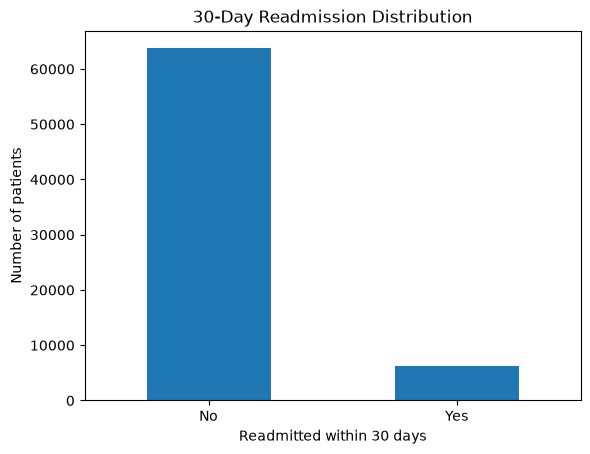

In [21]:
target_counts = df['readmitted_30'].value_counts().sort_index()

target_counts.plot(kind='bar')

plt.title('30-Day Readmission Distribution')
plt.xlabel('Readmitted within 30 days')
plt.ylabel('Number of patients')
plt.xticks([0, 1], ['No', 'Yes'], rotation=0)
plt.show()

In [22]:
target_rate = df['readmitted_30'].mean()
print(f'30-day readmission rate:{target_rate:.2%}')

30-day readmission rate:8.98%


### 4.2 Age and readmission

In [23]:
df['age'].value_counts().sort_index()

age
[0-10)        153
[10-20)       534
[20-30)      1121
[30-40)      2692
[40-50)      6828
[50-60)     12351
[60-70)     15689
[70-80)     17751
[80-90)     11110
[90-100)     1761
Name: count, dtype: int64

In [24]:
age_readmission = (
    df.groupby('age')['readmitted_30']
      .agg(['mean', 'count'])
      .sort_index()
)

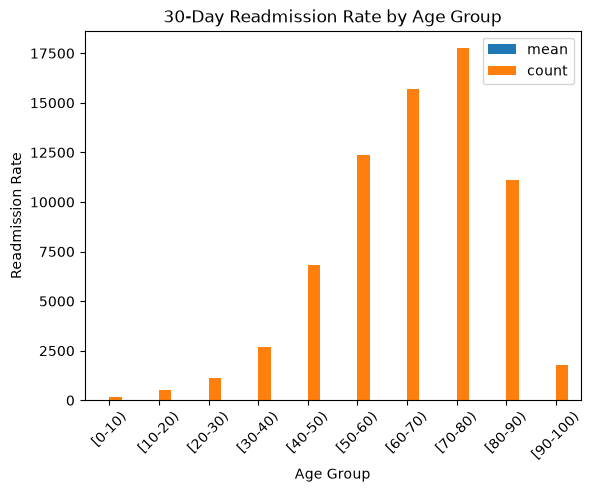

In [25]:
age_readmission.plot(kind='bar')

plt.title('30-Day Readmission Rate by Age Group')
plt.xlabel('Age Group')
plt.ylabel('Readmission Rate')
plt.xticks(rotation=45)
plt.show()

In [26]:
age_readmission

,mean,count
age,,
[0-10),0.019608,153
[10-20),0.048689,534
[20-30),0.074041,1121
[30-40),0.069837,2692
[40-50),0.074107,6828
[50-60),0.071249,12351
[60-70),0.090191,15689
[70-80),0.102360,17751
[80-90),0.107921,11110


### 4.3 Length of hospital stay and readmission

In [27]:
los_readmission = (
    df.groupby('time_in_hospital')['readmitted_30']
      .agg(['mean', 'count'])
)

los_readmission

,mean,count
time_in_hospital,,
1,0.065425,10470
2,0.076828,12183
3,0.082126,12493
4,0.088613,9423
5,0.097776,6699
6,0.108911,5050
7,0.114271,3903
8,0.123109,2843
9,0.122972,1911


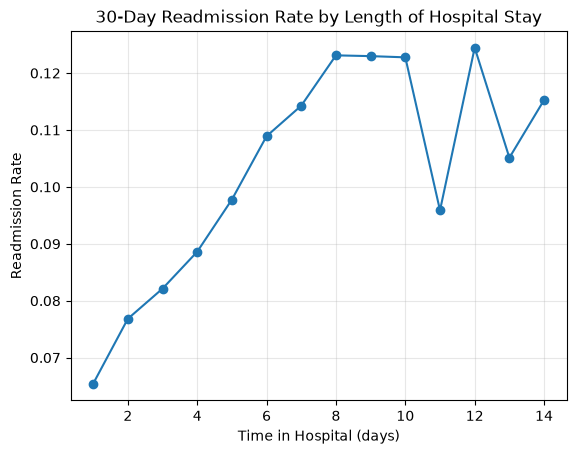

In [28]:
los_readmission['mean'].plot(marker='o')

plt.title('30-Day Readmission Rate by Length of Hospital Stay')
plt.xlabel('Time in Hospital (days)')
plt.ylabel('Readmission Rate')
plt.grid(alpha=0.3)
plt.show()

### 4.4 Previous inpatient visits and readmission

In [29]:
inpatient_readmission = (
    df.groupby('number_inpatient')['readmitted_30']
      .agg(['mean', 'count'])
)

inpatient_readmission

,mean,count
number_inpatient,,
0,0.081285,61795
1,0.128838,5798
2,0.185210,1501
3,0.237581,463
4,0.236842,228
5,0.284314,102
6,0.400000,55
7,0.473684,19
8,0.230769,13


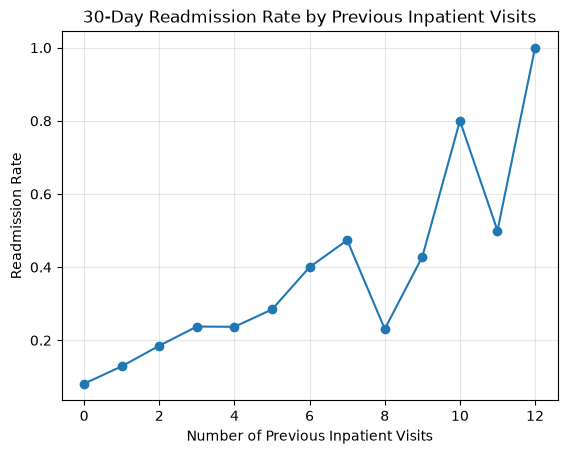

In [30]:
inpatient_readmission['mean'].plot(marker='o')

plt.title('30-Day Readmission Rate by Previous Inpatient Visits')
plt.xlabel('Number of Previous Inpatient Visits')
plt.ylabel('Readmission Rate')
plt.grid(alpha=0.3)
plt.show()

The 30-day readmission rate increases substantially as the number of previous inpatient visits rises. This suggests that prior hospital utilization is a strong indicator of future readmission risk.

However, the highest values of `number_inpatient` contain relatively few patients, which causes the readmission rates to fluctuate sharply. Therefore, the overall upward trend is more informative than the individual rates for the rare high-utilization groups.

In [31]:
inpatient_readmission.tail(8)

,mean,count
number_inpatient,,
5,0.284314,102
6,0.400000,55
7,0.473684,19
8,0.230769,13
9,0.428571,7
10,0.800000,5
11,0.500000,2
12,1.000000,2


In [32]:
df['inpatient_group'] = pd.cut(
    df['number_inpatient'],
    bins=[-1, 0, 1, 2, 3, np.inf],
    labels=['0', '1', '2', '3', '4+']
)

In [33]:
inpatient_group_readmission = (
    df.groupby('inpatient_group', observed=False)['readmitted_30']
      .agg(['mean', 'count'])
)

inpatient_group_readmission

,mean,count
inpatient_group,,
0,0.081285,61795
1,0.128838,5798
2,0.185210,1501
3,0.237581,463
4+,0.293303,433


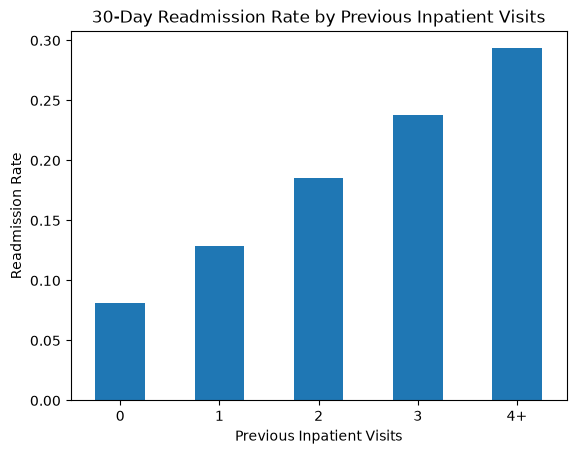

In [34]:
inpatient_group_readmission['mean'].plot(kind='bar')

plt.title('30-Day Readmission Rate by Previous Inpatient Visits')
plt.xlabel('Previous Inpatient Visits')
plt.ylabel('Readmission Rate')
plt.xticks(rotation=0)
plt.show()

Prior inpatient utilization shows a strong relationship with 30-day readmission. Patients with no previous inpatient visits had the lowest readmission rate, while the rate increased progressively among patients with repeated prior admissions.

The very high rates observed at the largest values of `number_inpatient` are based on very small sample sizes, so the grouped analysis provides a more stable view of the relationship.

### 4.5 Previous emergency and outpatient visits

In [35]:
emergency_readmission = (
    df.groupby('number_emergency')['readmitted_30']
      .agg(['mean', 'count'])
)

emergency_readmission.head(15)

,mean,count
number_emergency,,
0,0.087411,64889
1,0.112542,3883
2,0.134347,789
3,0.128099,242
4,0.242105,95
5,0.156250,32
6,0.230769,26
7,0.125000,8
8,0.222222,9


In [36]:
outpatient_readmission = (
    df.groupby('number_outpatient')['readmitted_30']
      .agg(['mean', 'count'])
)

outpatient_readmission.head(15)

,mean,count
number_outpatient,,
0,0.087994,60868
1,0.103556,4780
2,0.102926,1982
3,0.086679,1096
4,0.114983,574
5,0.114695,279
6,0.090164,122
7,0.097222,72
8,0.053571,56


In [37]:
df['emergency_group'] = pd.cut(
    df['number_emergency'],
    bins=[-1, 0, 1, 2, np.inf],
    labels=['0', '1', '2', '3+']
)

In [38]:
df['outpatient_group'] = pd.cut(
    df['number_outpatient'],
    bins=[-1, 0, 1, 2, np.inf],
    labels=['0', '1', '2', '3+']
)

In [39]:
emergency_group_readmission = (
    df.groupby('emergency_group', observed=False)['readmitted_30']
      .agg(['mean', 'count'])
)

emergency_group_readmission

,mean,count
emergency_group,,
0,0.087411,64889
1,0.112542,3883
2,0.134347,789
3+,0.163170,429


In [40]:
outpatient_group_readmission = (
    df.groupby('outpatient_group', observed=False)['readmitted_30']
      .agg(['mean', 'count'])
)
outpatient_group_readmission

,mean,count
outpatient_group,,
0,0.087994,60868
1,0.103556,4780
2,0.102926,1982
3+,0.097458,2360


Previous emergency department utilization shows a clear relationship with 30-day readmission. The readmission rate increases from about 8.7% among patients with no prior emergency visits to more than 16% among patients with three or more prior emergency visits.

Previous outpatient visits show a weaker relationship. Patients with outpatient visits have only slightly higher readmission rates than patients with none, and the rate does not increase consistently as the number of outpatient visits rises.

These results suggest that previous emergency utilization may be more informative for predicting 30-day readmission than outpatient utilization.

### 5. Feature Importance

In [41]:
from sklearn.metrics import mutual_info_score

In [42]:
def mutual_info_readmission_score(series):
    return mutual_info_score(series, df['readmitted_30'])

In [43]:
numerical = [
    'time_in_hospital',
    'num_lab_procedures',
    'num_procedures',
    'num_medications',
    'number_outpatient',
    'number_emergency',
    'number_inpatient',
    'number_diagnoses',
    'readmitted_30'
]

In [44]:
correlations = (
    df[numerical]
    .corr()['readmitted_30']
    .sort_values(ascending=False)
)
correlations

readmitted_30         1.000000
number_inpatient      0.100278
time_in_hospital      0.055824
number_diagnoses      0.045610
num_medications       0.036198
num_lab_procedures    0.032063
number_emergency      0.028022
number_outpatient     0.008633
num_procedures       -0.000280
Name: readmitted_30, dtype: float64

Among the numerical features, `number_inpatient` has the strongest positive correlation with 30-day readmission, although the correlation is still relatively modest.

`time_in_hospital`, `number_diagnoses`, and `num_medications` also show small positive relationships with readmission. `num_procedures` has almost no linear relationship with the target.

These low correlation values do not necessarily mean the features are unimportant. Pearson correlation only measures linear relationships, while machine-learning models may capture more complex and non-linear patterns.

In [45]:
eda_helper_columns = [
    'inpatient_group',
    'emergency_group',
    'outpatient_group'
]

In [46]:
categorical = [
    col for col in df.select_dtypes(
        include=['object', 'string', 'category']
    ).columns
    if col not in eda_helper_columns
]

categorical

['race',
 'gender',
 'age',
 'admission_type_id',
 'discharge_disposition_id',
 'admission_source_id',
 'medical_specialty',
 'diag_1',
 'diag_2',
 'diag_3',
 'metformin',
 'repaglinide',
 'nateglinide',
 'chlorpropamide',
 'glimepiride',
 'acetohexamide',
 'glipizide',
 'glyburide',
 'tolbutamide',
 'pioglitazone',
 'rosiglitazone',
 'acarbose',
 'miglitol',
 'troglitazone',
 'tolazamide',
 'insulin',
 'glyburide-metformin',
 'glipizide-metformin',
 'metformin-rosiglitazone',
 'metformin-pioglitazone',
 'change',
 'diabetesMed']

In [47]:
mi_scores = (
    df[categorical]
    .apply(mutual_info_readmission_score)
    .sort_values(ascending=False)
)

mi_scores

diag_1                      0.009842
diag_3                      0.008063
discharge_disposition_id    0.007605
diag_2                      0.007541
medical_specialty           0.001682
age                         0.001408
diabetesMed                 0.000398
insulin                     0.000350
admission_type_id           0.000148
admission_source_id         0.000147
repaglinide                 0.000138
race                        0.000138
change                      0.000105
metformin                   0.000103
glipizide                   0.000091
nateglinide                 0.000035
glimepiride                 0.000027
glyburide-metformin         0.000022
pioglitazone                0.000021
chlorpropamide              0.000020
acarbose                    0.000016
glyburide                   0.000012
rosiglitazone               0.000011
tolazamide                  0.000011
glipizide-metformin         0.000009
gender                      0.000006
miglitol                    0.000005
t

The diagnosis variables (`diag_1`, `diag_2`, and `diag_3`) have the highest mutual information scores among the categorical features, suggesting that diagnosis information contains the strongest categorical signal for 30-day readmission.

`medical_specialty` and `age` also show some relationship with the target, although their scores are considerably smaller.

Most medication-related categorical features have very low mutual information scores individually. This does not necessarily mean they are useless, because their predictive value may emerge through interactions with other variables in non-linear models.

## 6. Prepare Data for Modeling

In [48]:
df_model = df.drop(columns=eda_helper_columns)

In [49]:
y = df_model['readmitted_30']
X = df_model.drop(columns=['readmitted_30'])

In [50]:
from sklearn.model_selection import train_test_split

In [51]:
df_full_train, df_test = train_test_split(
    df_model, test_size=0.2, random_state=1,
    stratify=df_model.readmitted_30
)

In [52]:
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=1,
    stratify=df_full_train.readmitted_30
)

In [53]:
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

In [54]:
y_train = df_train.readmitted_30.values
y_val = df_val.readmitted_30.values
y_test = df_test.readmitted_30.values


In [55]:
del df_train['readmitted_30']
del df_val['readmitted_30']
del df_test['readmitted_30']

In [56]:
len(df_train), len(df_val), len(df_test)
y_train.mean(), y_val.mean(), y_test.mean()

(np.float64(0.08979854264894985),
 np.float64(0.08979854264894985),
 np.float64(0.08979854264894985))

## 7. Baseline model: Logistic Regression

In [57]:
categorical = list(df_train.select_dtypes(include=['object', 'string', 'category']).columns)

numerical = list(
    df_train.select_dtypes(include=['int64', 'float64']).columns
)

categorical, numerical

(['race',
  'gender',
  'age',
  'admission_type_id',
  'discharge_disposition_id',
  'admission_source_id',
  'medical_specialty',
  'diag_1',
  'diag_2',
  'diag_3',
  'metformin',
  'repaglinide',
  'nateglinide',
  'chlorpropamide',
  'glimepiride',
  'acetohexamide',
  'glipizide',
  'glyburide',
  'tolbutamide',
  'pioglitazone',
  'rosiglitazone',
  'acarbose',
  'miglitol',
  'troglitazone',
  'tolazamide',
  'insulin',
  'glyburide-metformin',
  'glipizide-metformin',
  'metformin-rosiglitazone',
  'metformin-pioglitazone',
  'change',
  'diabetesMed'],
 ['time_in_hospital',
  'num_lab_procedures',
  'num_procedures',
  'num_medications',
  'number_outpatient',
  'number_emergency',
  'number_inpatient',
  'number_diagnoses'])

In [58]:
train_dicts = df_train[categorical + numerical].to_dict(orient='records')
val_dicts = df_val[categorical + numerical].to_dict(orient='records')

In [59]:
from sklearn.feature_extraction import DictVectorizer

dv = DictVectorizer(sparse=False)

X_train = dv.fit_transform(train_dicts)
X_val = dv.transform(val_dicts)

In [60]:
X_train.shape, X_val.shape

((41994, 2199), (13998, 2199))

In [61]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(
    solver='liblinear',
    max_iter=1000
)

model.fit(X_train, y_train)

,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass` problems (`n_classes >= 3`), all solvers except 'liblinear' minimize the full multinomial loss, 'liblinear' will raise an error.- 'newton-cholesky' is a good choice for `n_samples` >> `n_features * n_classes`, especially with one-hot encoded categorical features with rare categories. Be aware that the memory usage of this solver has a quadratic dependency on `n_features * n_classes` because it explicitly computes the full Hessian matrix.- For small datasets, 'liblinear' is a good choice, whereas 'sag' and 'saga' are faster for large ones;- 'liblinear' can only handle binary classification by default. To apply a one-versus-rest scheme for the multiclass setting one can wrap it with the :class:`~sklearn.multiclass.OneVsRestClassifier`... warning:: The choice of the algorithm depends on the penalty chosen (`l1_ratio=0` for L2-penalty, `l1_ratio=1` for L1-penalty and `0 < l1_ratio < 1` for Elastic-Net) and on (multinomial) multiclass support: ================= ======================== ====================== solver l1_ratio multinomial multiclass ================= ======================== ====================== 'lbfgs' l1_ratio=0 yes 'liblinear' l1_ratio=1 or l1_ratio=0 no 'newton-cg' l1_ratio=0 yes 'newton-cholesky' l1_ratio=0 yes 'sag' l1_ratio=0 yes 'saga' 0<=l1_ratio<=1 yes ================= ======================== ======================.. note:: 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`... seealso:: Refer to the :ref:`User Guide <Logistic_regression>` for more information regarding :class:`LogisticRegression` and more specifically the :ref:`Table <logistic_regression_solvers>` summarizing solver/penalty supports... versionadded:: 0.17 Stochastic Average Gradient (SAG) descent solver. Multinomial support in version 0.18... versionadded:: 0.19 SAGA solver... versionchanged:: 0.22 The default solver changed from 'liblinear' to 'lbfgs' in 0.22... versionadded:: 1.2 newton-cholesky solver. Multinomial support in version 1.6.",'liblinear'
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalt

In [62]:
y_pred = model.predict_proba(X_val)[:, 1]

In [63]:
from sklearn.metrics import roc_auc_score

auc = roc_auc_score(y_val, y_pred)
auc

0.6313847695819977

In [64]:
y_pred_binary = (y_pred >= 0.5).astype(int)

In [65]:
from sklearn.metrics import precision_score, recall_score, f1_score, confusion_matrix

print("Precision:", precision_score(y_val, y_pred_binary))
print("Recall:", recall_score(y_val, y_pred_binary))
print("F1:", f1_score(y_val, y_pred_binary))
print("Confusion matrix:")
print(confusion_matrix(y_val, y_pred_binary))

Precision: 0.3235294117647059
Recall: 0.008750994431185362
F1: 0.017041053446940357
Confusion matrix:
[[12718    23]
 [ 1246    11]]


In [66]:
thresholds = np.linspace(0, 0.5, 21)

for t in thresholds:
    actual_positive = (y_val == 1)
    actual_negative = (y_val == 0)

    predict_positive = (y_pred >= t)
    predict_negative = (y_pred < t)

    tp = (predict_positive & actual_positive).sum()
    tn = (predict_negative & actual_negative).sum()
    fp = (predict_positive & actual_negative).sum()
    fn = (predict_negative & actual_positive).sum()

    precision = tp / (tp + fp) if (tp + fp) > 0 else 0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0

    print(
        f"{t:.2f}  precision={precision:.3f}  recall={recall:.3f}"
    )

0.00  precision=0.090  recall=1.000
0.03  precision=0.092  recall=0.973
0.05  precision=0.104  recall=0.834
0.08  precision=0.121  recall=0.628
0.10  precision=0.142  recall=0.467
0.12  precision=0.159  recall=0.340
0.15  precision=0.183  recall=0.264
0.18  precision=0.209  recall=0.206
0.20  precision=0.231  recall=0.169
0.23  precision=0.253  recall=0.135
0.25  precision=0.266  recall=0.113
0.28  precision=0.286  recall=0.092
0.30  precision=0.307  recall=0.077
0.33  precision=0.285  recall=0.054
0.35  precision=0.296  recall=0.042
0.38  precision=0.305  recall=0.034
0.40  precision=0.295  recall=0.025
0.43  precision=0.296  recall=0.019
0.45  precision=0.283  recall=0.014
0.48  precision=0.311  recall=0.011
0.50  precision=0.324  recall=0.009


Lowering the classification threshold substantially improves recall. At a threshold of 0.10, the model identifies about 47% of true 30-day readmissions, compared with less than 1% at the default threshold of 0.50.

However, precision remains relatively low. This illustrates the tradeoff between identifying more high-risk patients and generating more false-positive predictions.

For comparing models, ROC AUC will remain the primary threshold-independent metric. Threshold selection will be revisited after selecting the best model.

In [67]:
thresholds = np.linspace(0.05, 0.30, 26)

scores = []

for t in thresholds:
    predict_positive = (y_pred >= t)

    tp = ((predict_positive == 1) & (y_val == 1)).sum()
    fp = ((predict_positive == 1) & (y_val == 0)).sum()
    fn = ((predict_positive == 0) & (y_val == 1)).sum()

    precision = tp / (tp + fp) if (tp + fp) > 0 else 0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0

    f1 = (
        2 * precision * recall / (precision + recall)
        if (precision + recall) > 0
        else 0
    )

    scores.append((t, precision, recall, f1))

In [68]:
df_scores = pd.DataFrame(
    scores,
    columns=['threshold', 'precision', 'recall', 'f1']
)

df_scores.sort_values('f1', ascending=False).head()

,threshold,precision,recall,f1
8,0.13,0.164782,0.324582,0.218591
6,0.11,0.148297,0.412092,0.218105
5,0.10,0.141822,0.466985,0.217569
10,0.15,0.183324,0.264121,0.216428
9,0.14,0.171808,0.287987,0.215220


The best F1-score for the baseline Logistic Regression model occurs at a threshold of approximately 0.12.

At this threshold, recall improves substantially compared with the default threshold of 0.50, although precision remains relatively low. This reinforces that threshold selection matters for this imbalanced classification problem.

For model selection, ROC AUC will remain the primary metric because it evaluates ranking performance independently of a specific classification threshold.

## 8. Decision Tree

In [69]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import roc_auc_score

In [70]:
dt = DecisionTreeClassifier(
    max_depth=5,
    min_samples_leaf=20,
    random_state=1
)
dt.fit(X_train, y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",5
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",20
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",1
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in

In [71]:
y_pred = dt.predict_proba(X_val)[:, 1]

roc_auc_score(y_val, y_pred)

0.6139918317558242

In [72]:
for depth in [3, 4, 5, 6, 8, 10, None]:
    dt = DecisionTreeClassifier(
        max_depth=depth,
        min_samples_leaf=20,
        random_state=1
    )

    dt.fit(X_train, y_train)

    y_pred = dt.predict_proba(X_val)[:, 1]
    auc = roc_auc_score(y_val, y_pred)

    print(f"depth={depth}, auc={auc:.3f}")

depth=3, auc=0.595
depth=4, auc=0.607
depth=5, auc=0.614
depth=6, auc=0.620
depth=8, auc=0.615
depth=10, auc=0.612
depth=None, auc=0.573


In [73]:
scores = []

for depth in [3, 4, 5, 6, 8, 10]:
    for leaf in [1, 5, 10, 20, 50, 100, 200]:

        dt = DecisionTreeClassifier(
            max_depth=depth,
            min_samples_leaf=leaf,
            random_state=1
        )

        dt.fit(X_train, y_train)

        y_pred = dt.predict_proba(X_val)[:, 1]
        auc = roc_auc_score(y_val, y_pred)

        scores.append((depth, leaf, auc))

In [74]:
df_dt_scores = pd.DataFrame(
    scores,
    columns=['max_depth', 'min_samples_leaf', 'auc']
)

df_dt_scores.sort_values('auc', ascending=False).head(10)

,max_depth,min_samples_leaf,auc
24,6,20,0.620168
41,10,200,0.619677
34,8,200,0.618507
26,6,100,0.618495
30,8,10,0.618443
23,6,10,0.616927
25,6,50,0.615930
27,6,200,0.615573
31,8,20,0.615317
40,10,100,0.614939


## 9. Random Forest

In [75]:
from sklearn.ensemble import RandomForestClassifier

In [76]:
rf = RandomForestClassifier(
    n_estimators=100,
    max_depth=10,
    min_samples_leaf=5,
    random_state=1,
    n_jobs=-1
)

rf.fit(X_train, y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",10
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",5
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",1
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total nu

In [77]:
y_pred = rf.predict_proba(X_val)[:, 1]

roc_auc_score(y_val, y_pred)

0.6368960147637557

In [78]:
scores = []

for n in [10, 50, 100, 200, 300]:
    rf = RandomForestClassifier(
        n_estimators=n,
        max_depth=10,
        min_samples_leaf=5,
        random_state=1,
        n_jobs=-1
    )

    rf.fit(X_train, y_train)

    y_pred = rf.predict_proba(X_val)[:, 1]
    auc = roc_auc_score(y_val, y_pred)

    scores.append((n, auc))

In [79]:
df_rf_n = pd.DataFrame(
    scores,
    columns=['n_estimators', 'auc']
)

df_rf_n

,n_estimators,auc
0,10,0.628260
1,50,0.635636
2,100,0.636896
3,200,0.638626
4,300,0.638744


Increasing the number of trees improved validation ROC AUC, but the improvement became very small beyond 200 trees.

To balance predictive performance and training time, 200 trees were selected for further tuning.

## tune max_depth

In [80]:
scores = []

for depth in [5, 8, 10, 12, 15, 20, None]:

    rf = RandomForestClassifier(
        n_estimators=200,
        max_depth=depth,
        min_samples_leaf=5,
        random_state=1,
        n_jobs=-1
    )

    rf.fit(X_train, y_train)

    y_pred = rf.predict_proba(X_val)[:, 1]
    auc = roc_auc_score(y_val, y_pred)

    scores.append((depth, auc))

In [81]:
df_rf_depth = pd.DataFrame(
    scores,
    columns=['max_depth', 'auc']
)

df_rf_depth

,max_depth,auc
0,5.0,0.634983
1,8.0,0.637615
2,10.0,0.638626
3,12.0,0.639276
4,15.0,0.642098
5,20.0,0.642826
6,NaN,0.647423


Increasing `max_depth` improved validation ROC AUC. The best result was obtained with no explicit depth limit (`max_depth=None`), reaching an AUC of approximately 0.640.

This suggests that deeper trees are capturing additional non-linear relationships in the data. However, deeper trees can also increase the risk of overfitting, so `min_samples_leaf` will be tuned next to regularize the forest.

In [82]:
n_estimators=200
max_depth=None

In [83]:
scores = []

for leaf in [1, 2, 5, 10, 20, 50, 100]:

    rf = RandomForestClassifier(
        n_estimators=200,
        max_depth=None,
        min_samples_leaf=leaf,
        random_state=1,
        n_jobs=-1
    )

    rf.fit(X_train, y_train)

    y_pred = rf.predict_proba(X_val)[:, 1]
    auc = roc_auc_score(y_val, y_pred)

    scores.append((leaf, auc))

In [84]:
df_rf_leaf = pd.DataFrame(
    scores,
    columns=['min_samples_leaf', 'auc']
)

df_rf_leaf

,min_samples_leaf,auc
0,1,0.626412
1,2,0.643389
2,5,0.647423
3,10,0.645060
4,20,0.641274
5,50,0.634707
6,100,0.633128


The tuned Random Forest achieved the best validation ROC AUC so far, approximately 0.647.

The strongest result was obtained with `min_samples_leaf=5`. Smaller leaves slightly reduced generalization, while larger leaves regularized the model too aggressively and lowered predictive performance.

In [85]:
rf_final = RandomForestClassifier(
    n_estimators=200,
    max_depth=None,
    min_samples_leaf=5,
    random_state=1,
    n_jobs=-1
)

rf_final.fit(X_train, y_train)

y_pred = rf_final.predict_proba(X_val)[:, 1]

rf_auc = roc_auc_score(y_val, y_pred)

rf_auc

0.6474227334539794

In [86]:
print(df_test.iloc[0].to_json(indent=2))

{
  "race":"Caucasian",
  "gender":"Female",
  "age":"[80-90)",
  "admission_type_id":"1",
  "discharge_disposition_id":"1",
  "admission_source_id":"7",
  "time_in_hospital":3,
  "medical_specialty":"unknown",
  "num_lab_procedures":37,
  "num_procedures":1,
  "num_medications":14,
  "number_outpatient":0,
  "number_emergency":0,
  "number_inpatient":1,
  "diag_1":"53",
  "diag_2":"462",
  "diag_3":"53",
  "number_diagnoses":7,
  "metformin":"No",
  "repaglinide":"No",
  "nateglinide":"No",
  "chlorpropamide":"No",
  "glimepiride":"No",
  "acetohexamide":"No",
  "glipizide":"No",
  "glyburide":"No",
  "tolbutamide":"No",
  "pioglitazone":"No",
  "rosiglitazone":"No",
  "acarbose":"No",
  "miglitol":"No",
  "troglitazone":"No",
  "tolazamide":"No",
  "insulin":"Steady",
  "glyburide-metformin":"No",
  "glipizide-metformin":"No",
  "metformin-rosiglitazone":"No",
  "metformin-pioglitazone":"No",
  "change":"No",
  "diabetesMed":"Yes"
}


## 11. Final model and test evaluation

In [87]:
df_full_train = df_full_train.reset_index(drop=True)
y_full_train = df_full_train.readmitted_30.values
del df_full_train['readmitted_30']

In [88]:
dicts_full = df_full_train.to_dict(orient='records')
dv_full = DictVectorizer(sparse=False)
X_full = dv_full.fit_transform(dicts_full)

rf_test = RandomForestClassifier(
    n_estimators=200, max_depth=None, min_samples_leaf=5,
    random_state=1, n_jobs=-1
)
rf_test.fit(X_full, y_full_train)

X_test_m = dv_full.transform(df_test.to_dict(orient='records'))
y_pred_test = rf_test.predict_proba(X_test_m)[:, 1]

print(f'test auc: {roc_auc_score(y_test, y_pred_test):.4f}')

test auc: 0.6595
